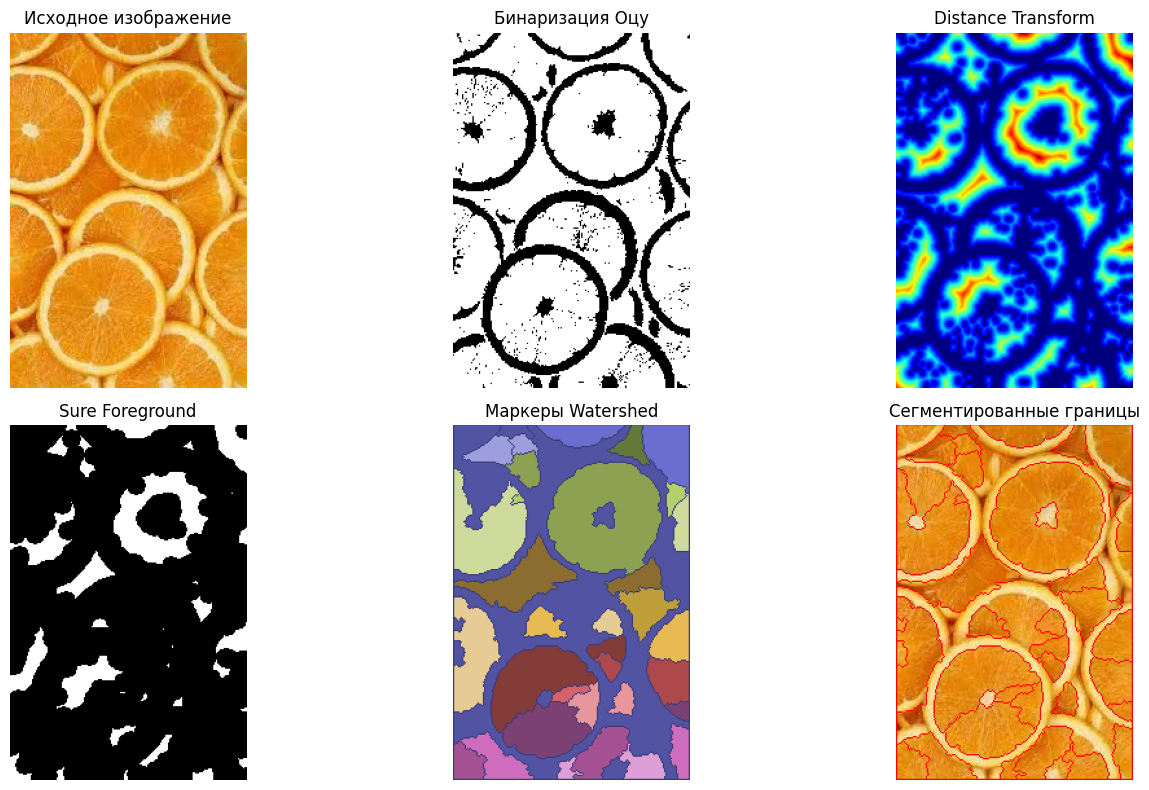

In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Проверка наличия исходных переменных
if "image_gray" not in globals() or "thresh" not in globals():
  img_raw = cv2.imread("oranges_1.jpg")
  image_gray = cv2.cvtColor(img_raw, cv2.COLOR_BGR2GRAY)
  _, thresh = cv2.threshold(
      image_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
  )

# 1. Морфологическое удаление мелкого фонового шума
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# 2. Определение области достоверного фона (Sure Background)
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# 3. Преобразование расстояний (Distance Transform)
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)

# Порог по расстоянию для нахождения надежного переднего плана (Sure Foreground)
_, sure_fg = cv2.threshold(dist_transform, 0.4 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

# 4. Область неопределенности
unknown = cv2.subtract(sure_bg, sure_fg)

# 5. Маркировка связных компонент
num_markers, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# 6. Watershed
img_color = cv2.imread("oranges_1.jpg")
markers = cv2.watershed(img_color, markers)

img_result = img_color.copy()
img_result[markers == -1] = [0, 0, 255]  # Границы красным цветом

# Визуализация
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.title("Исходное изображение")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(thresh, cmap="gray")
plt.title("Бинаризация Оцу")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(dist_transform, cmap="jet")
plt.title("Distance Transform")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(sure_fg, cmap="gray")
plt.title("Sure Foreground")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(markers, cmap="tab20b")
plt.title("Маркеры Watershed")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB))
plt.title("Сегментированные границы")
plt.axis("off")

plt.tight_layout()
plt.show()

Обнаружено деревьев на участке: 86


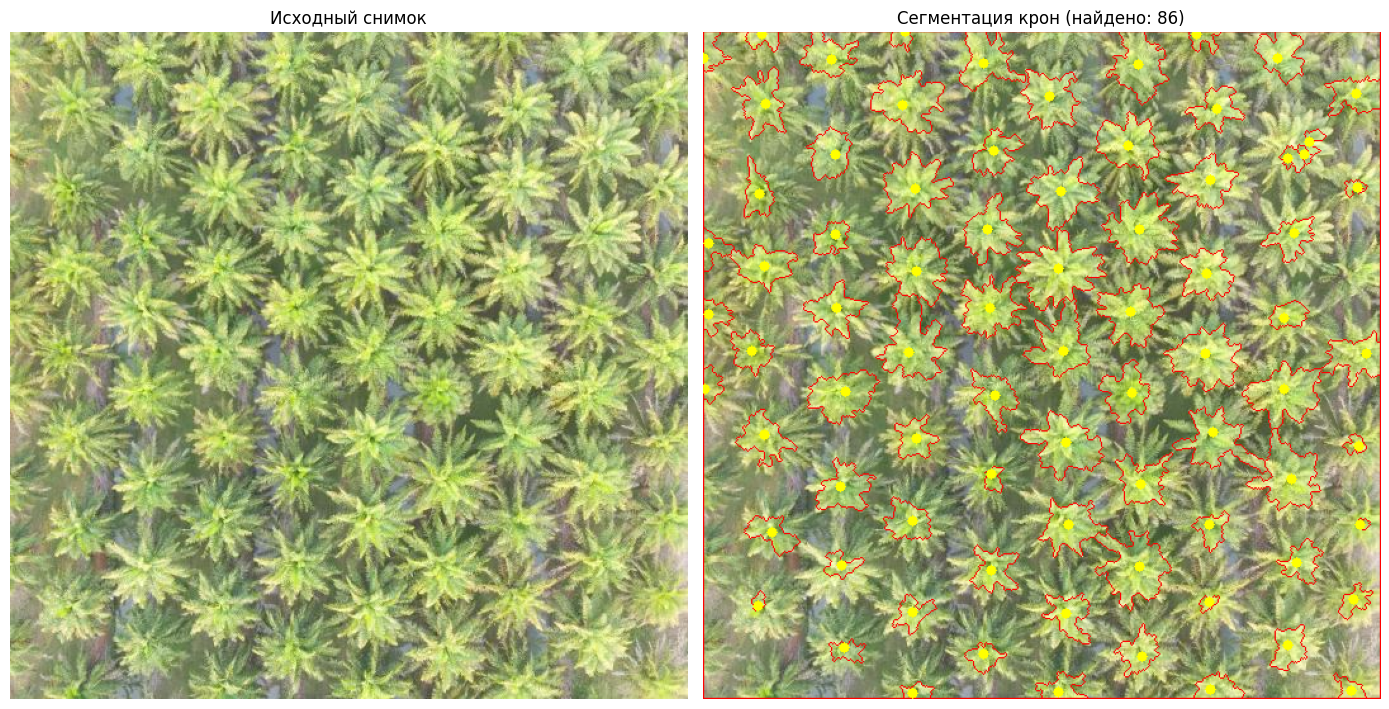

In [6]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Проверка имени файла на диске
filename = "palm_1.JPG" if os.path.exists("palm_1.JPG") else "palm_1_2.JPG"
palm_bgr = cv2.imread(filename)
palm_rgb = cv2.cvtColor(palm_bgr, cv2.COLOR_BGR2RGB)

# Вычисление индекса Excess Green (2*G - R - B)
R = palm_bgr[:, :, 2].astype(np.float32)
G = palm_bgr[:, :, 1].astype(np.float32)
B = palm_bgr[:, :, 0].astype(np.float32)
exg = 2 * G - R - B
exg_norm = cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Сглаживание и бинаризация
blurred_palm = cv2.GaussianBlur(exg_norm, (9, 9), 2)
_, palm_thresh = cv2.threshold(
    blurred_palm, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
palm_clean = cv2.morphologyEx(
    palm_thresh, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8)
)

# Преобразование расстояний и поиск центров крон
palm_dist = cv2.distanceTransform(palm_clean, cv2.DIST_L2, 5)
_, palm_peaks = cv2.threshold(palm_dist, 0.45 * palm_dist.max(), 255, 0)
palm_peaks = np.uint8(palm_peaks)

# Маркировка компонент
num_trees, tree_markers = cv2.connectedComponents(palm_peaks)
palm_bg = cv2.dilate(palm_clean, np.ones((3, 3), np.uint8), iterations=2)
tree_unknown = cv2.subtract(palm_bg, palm_peaks)

tree_markers = tree_markers + 1
tree_markers[tree_unknown == 255] = 0

# Сегментация Watershed
tree_markers = cv2.watershed(palm_bgr, tree_markers)

palm_detection = palm_rgb.copy()
palm_detection[tree_markers == -1] = [255, 0, 0]

# Подсчет и центрирование меток
contours, _ = cv2.findContours(
    palm_peaks, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
for c in contours:
  M = cv2.moments(c)
  if M["m00"] != 0:
    cX = int(M["m10"] / M["m00"])
    cY = int(M["m01"] / M["m00"])
    cv2.circle(palm_detection, (cX, cY), 4, (255, 255, 0), -1)

print(f"Обнаружено деревьев на участке: {len(contours)}")

plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1)
plt.imshow(palm_rgb)
plt.title("Исходный снимок")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(palm_detection)
plt.title(f"Сегментация крон (найдено: {len(contours)})")
plt.axis("off")

plt.tight_layout()
plt.show()

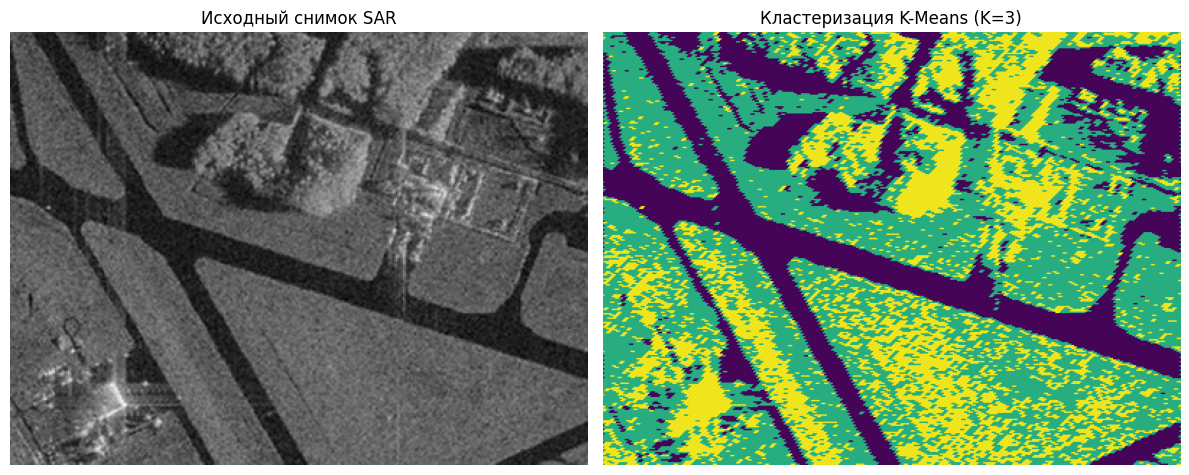

In [7]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Проверка имени файла на диске
sar_filename = "sar_1.jpg" if os.path.exists("sar_1.jpg") else "sar_1_2.jpg"
image = cv2.imread(sar_filename)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Пересчет K-Means если res2 еще не существует
if "res2" not in globals():
  z = image_gray.reshape((-1, 3) if len(image.shape) == 3 else (-1, 1))
  z = np.float32(z)
  criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
  K = 3
  ret, label, center = cv2.kmeans(
      z, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS
  )
  center = np.uint8(center)
  res = center[label.flatten()]
  res2 = res.reshape(image_gray.shape)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap="gray")
plt.title("Исходный снимок SAR")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(res2, cmap="viridis")
plt.title("Кластеризация K-Means (K=3)")
plt.axis("off")

plt.tight_layout()
plt.show()